In [1]:
import numpy as np
import matplotlib.pyplot as plt
from session_data import *
from visualize import *
from antenna_array import *

session_dir = Path("../data/2025-11-16/rotation_80_direct")
session = SessionData.from_directory(session_dir)
session.load_all_router_batches()
print(session.summary())

channel_data = np.zeros((1, 16), dtype=np.complex128)

for dp in session.data_points:
    # Check if router batch is loaded
    if dp.router_batch is None:
        continue
        
    csi_data = dp.router_batch.csi_processed_data
    
    # Check if CSI data is not empty and has the right shape
    if csi_data.size == 0 or len(csi_data.shape) < 2:
        continue
    
    channel_data = np.vstack((channel_data, csi_data))

num_samples = channel_data.shape[0] - 1
valid_antennas = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13, 21, 23, 25, 27]


num_samples = int(np.shape(channel_data)[0] / 10)
theta_vals = np.linspace(-80, 80, num_samples)
theta_vals = np.deg2rad(theta_vals)

# Create antenna arrays for each sample
spacing = 0.58 * 58.32 / 60.48
antenna_arrays = [AntennaArray() for _ in range(num_samples)]
antenna_arrays_real = [AntennaArray() for _ in range(num_samples)]
for i in range(num_samples):
    averaged_channel_data = np.mean(channel_data[i*10:(i+1)*10, :], axis=0)

    for antenna in range(32):
        if antenna not in valid_antennas:
            continue
        antenna_arrays[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
            0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)
        antenna_arrays_real[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
            0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)

    w = antenna_arrays[i].get_conjugate_beamformer(az=theta_vals[i], el=0)
    antenna_arrays[i].set_weights(w)
    antenna_arrays_real[i].set_weights(np.conjugate(averaged_channel_data))

Session: session_130954
Start: 2025-11-16 13:09:54.406331
End: 2025-11-16 13:22:26.440133
Duration: 752.0 seconds
Total Samples: 161
Data Points: 161
Images: 161



In [37]:
# Notes
"""
So we have the real-world antenna array and the ideal antenna array that are pointed towards the theta_vals[i] angle.
We can get the element factor for each element by dividing the real-world antenna array by the ideal antenna array at each theta and phi to get R(theta, phi).
"""

R = np.zeros((num_samples, 16, 512, 512), dtype=np.complex128)
theta_range = np.linspace(-np.pi/2, np.pi/2, 512)
phi_range = np.linspace(-np.pi/2, np.pi/2, 512)

for i in range(num_samples):
    for j, theta in enumerate(theta_range):
        for k, phi in enumerate(phi_range):
            R[i,:, j, k] = antenna_arrays[i].get_array_response(theta, phi) / antenna_arrays_real[i].get_array_response(theta, phi)

    print(f"Progress: {i/num_samples*100}%")

Progress: 0.0%
Progress: 0.628930817610063%
Progress: 1.257861635220126%
Progress: 1.8867924528301887%
Progress: 2.515723270440252%
Progress: 3.1446540880503147%
Progress: 3.7735849056603774%
Progress: 4.40251572327044%
Progress: 5.031446540880504%
Progress: 5.660377358490567%
Progress: 6.289308176100629%
Progress: 6.918238993710692%
Progress: 7.547169811320755%
Progress: 8.176100628930817%
Progress: 8.80503144654088%
Progress: 9.433962264150944%
Progress: 10.062893081761008%
Progress: 10.69182389937107%
Progress: 11.320754716981133%
Progress: 11.949685534591195%
Progress: 12.578616352201259%
Progress: 13.20754716981132%
Progress: 13.836477987421384%
Progress: 14.465408805031446%
Progress: 15.09433962264151%
Progress: 15.723270440251572%
Progress: 16.352201257861633%
Progress: 16.9811320754717%
Progress: 17.61006289308176%
Progress: 18.238993710691823%
Progress: 18.867924528301888%
Progress: 19.49685534591195%
Progress: 20.125786163522015%
Progress: 20.754716981132077%
Progress: 21.383

In [40]:
R_avg = np.mean(R, axis=0)

In [41]:
R_avg.shape

(16, 512, 512)

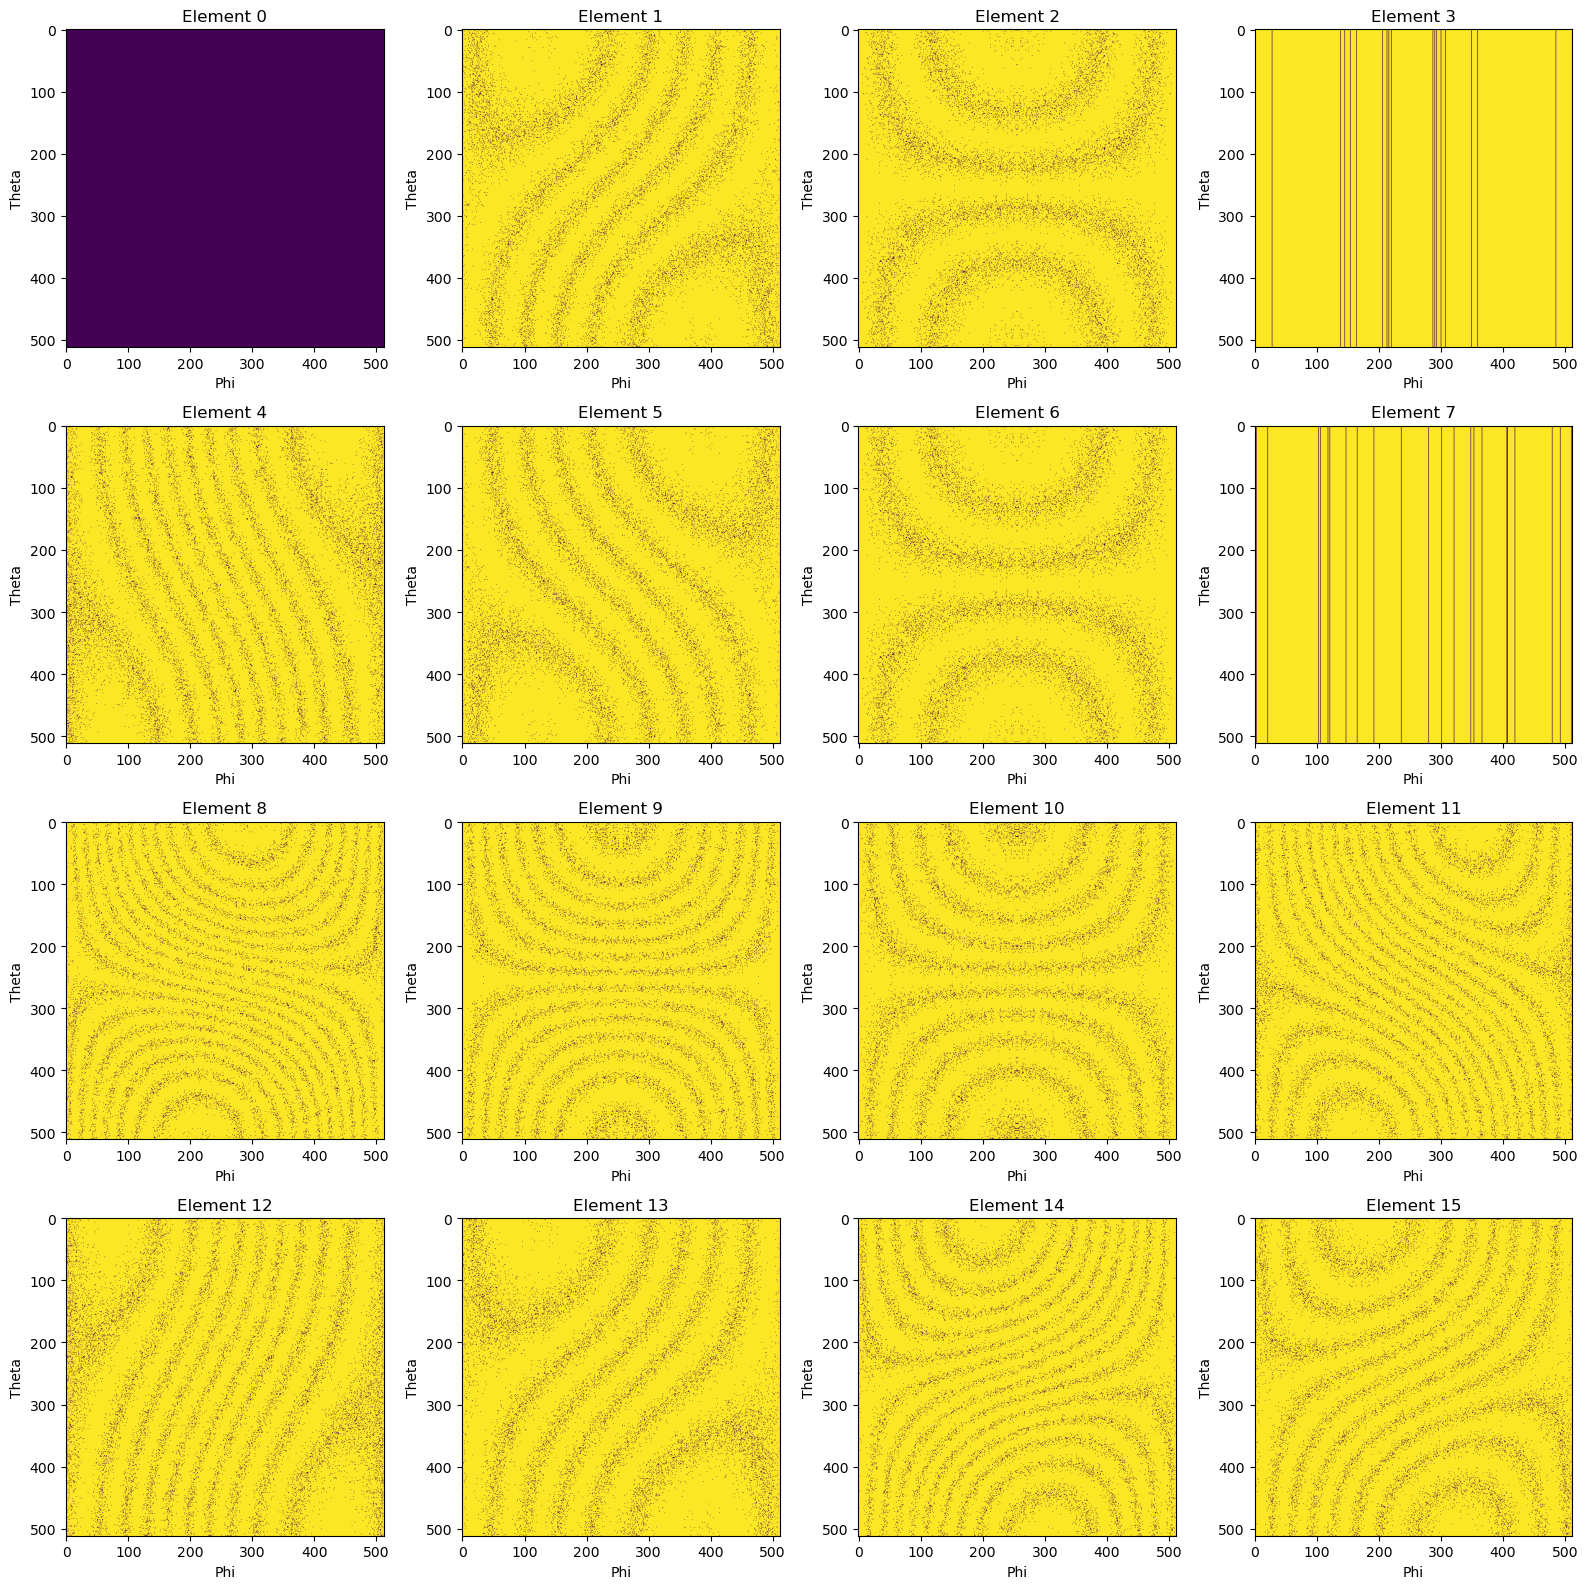

In [43]:
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(10*np.log10(np.abs(R_avg[i, :, :])), cmap='viridis')
    ax.set_xlabel(f"Phi")
    ax.set_ylabel(f"Theta")
    ax.set_title(f"Element {i}")
plt.tight_layout()
plt.show()

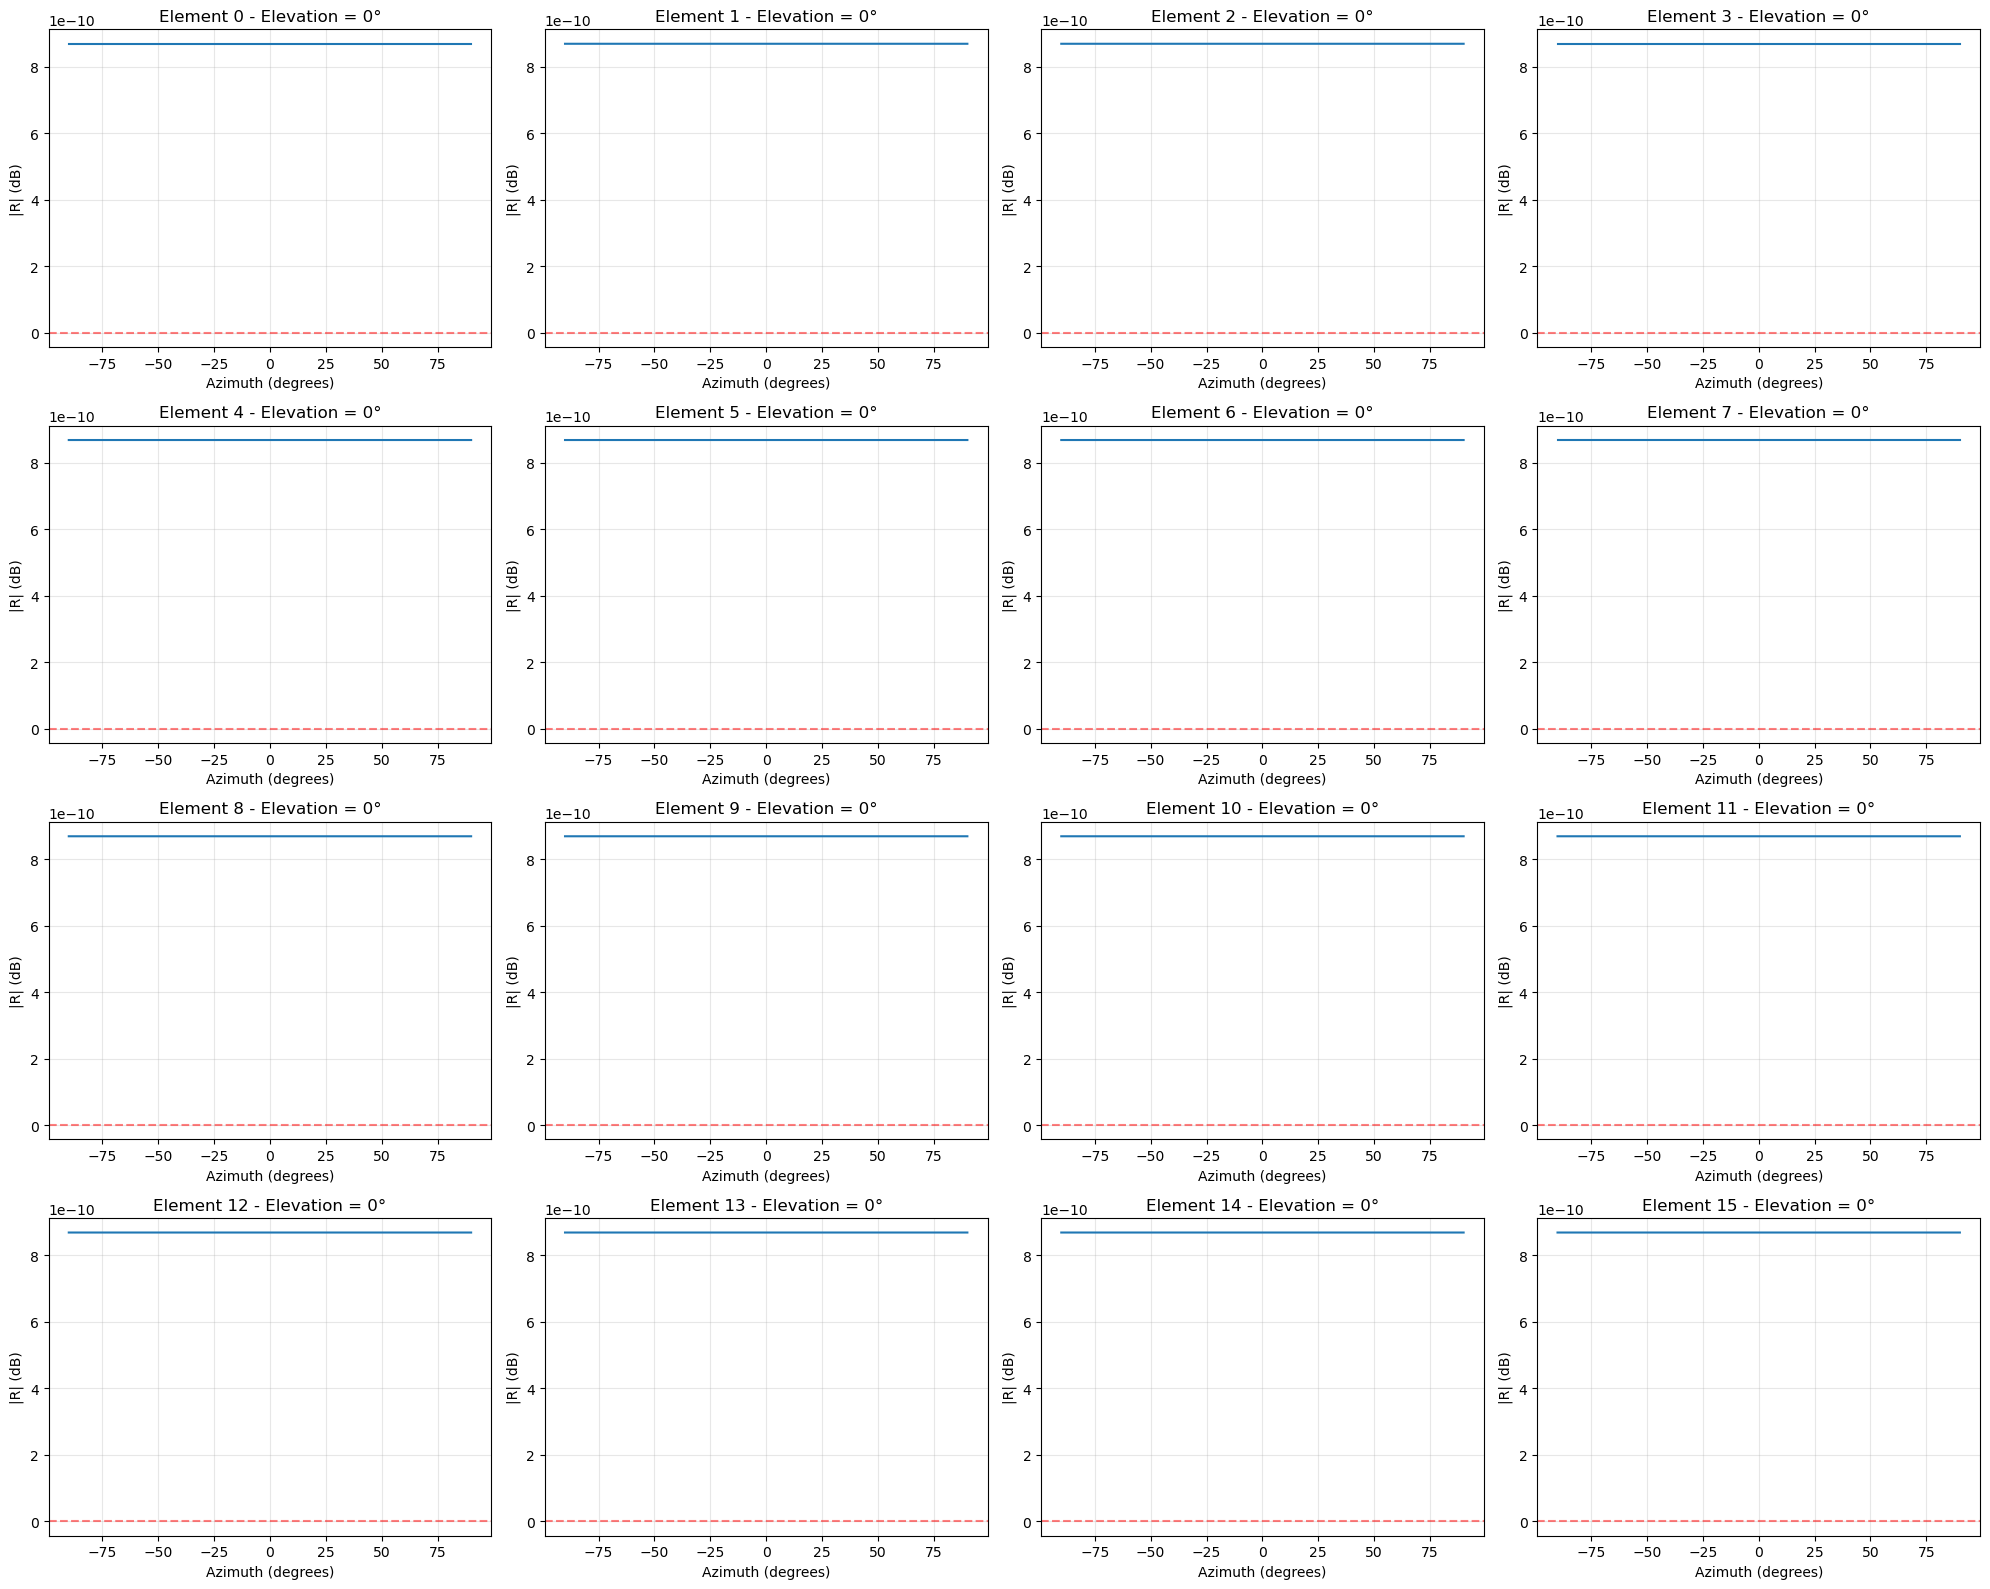

In [51]:
# Plot R (element factor) with elevation = 0 for all antenna elements
# R has shape: (num_samples, 16, 512, 512) -> (samples, antennas, theta, phi)
# Elevation = 0 means phi = 0, which is the middle index of phi_range

phi_idx = 256  # Middle index corresponding to phi = 0

# Plot R_avg at elevation = 0 for all 16 antenna elements
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for i, ax in enumerate(axes.flatten()):
    # Extract R at elevation = 0 (phi_idx = 256)
    R_slice = R_avg[i, :, phi_idx]
    
    # Convert to dB
    R_db = 20 * np.log10(np.abs(R_slice) + 1e-10)
    
    # Plot
    ax.plot(np.rad2deg(theta_range), R_db)
    ax.set_xlabel('Azimuth (degrees)', fontsize=10)
    ax.set_ylabel('|R| (dB)', fontsize=10)
    ax.set_title(f'Element {i} - Elevation = 0°', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()